# Encontro 11 — Potencial, alocação e restrições

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lambdageo-edu/curso-modelagem-dinamica-espacial/blob/main/docs/notebooks/encontro11_potencial_alocacao.ipynb)

Sem Python instalado? O selo acima abre este notebook no Google Colab, no navegador. Lá, use *Arquivo → Salvar uma cópia no Drive* antes de mudar qualquer coisa: sem a cópia, o que você escrever se perde ao fechar a página.

No encontro 9 os coeficientes do potencial vieram prontos no script do lab01. No encontro 10 vimos, numa nuvem de pontos, que o desmatamento cai com a distância às rodovias. Hoje juntamos as duas coisas e abrimos as outras duas peças do modelo:

1. **potencial**: de onde vêm os coeficientes, e o que eles dizem;
2. **alocação contínua × discreta**: frações de cada classe na célula, ou uma classe por célula;
3. **restrições**: proibir a mudança numa parte da área, e para onde ela vai.

Usamos dois labs do LuccME: o lab01 (Acre, frações, já conhecido) e o lab15 (Mojuí dos Campos, no Pará, uma classe por célula).

🔧 = troque um valor e rode de novo; ✏️ = responda.

## 0. Preparação

No Colab, a célula abaixo instala o DisSModel, o DisSLUCC e o `statsmodels` (cerca de 1 minuto). No laboratório o ambiente já está instalado e ela não instala nada.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q "dissmodel==0.6.6" "disslucc==0.5.0" statsmodels

import contextlib, copy, hashlib, io, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from dissmodel.core import Environment, Model
from dissmodel.geo.raster.backend import RasterBackend
from disslucc import (AllocationClueLike, AllocationDClueSLike, AllocationSpec, DemandPreComputedValues,
                      LogisticRegressionSpec, PotentialDLogisticRegression, PotentialLinearRegression,
                      RegressionSpec)

Os dados vêm do `luccme-goldens` v1.1.0 (DOI 10.5281/zenodo.23161342), com o hash conferido como nos encontros anteriores.

In [2]:
GOLDENS = "https://raw.githubusercontent.com/LambdaGeo/luccme-goldens/v1.1.0/"
ARQUIVOS = {
    "sources/labs/data/csAC.shp": "c43ca9d839bb3e7b7c503b7e85212ab5a828f6e1710d57297dbf23afa4cbb2b1",
    "sources/labs/data/csAC.dbf": "7992ebdc67fd66a59917c26a685a36448bf9c5dc4b885bbb8c9ce5e2d55b9f8e",
    "sources/labs/data/csAC.shx": "2eba45b6f20dd3eec8a7e9d401e21a14a0ab49d93edd280af485a58b2426fc98",
    "sources/labs/data/csAC.prj": "e908f36376343a9fc35faf56c02ce51c3c9d59b154f617f38992c092f2ee03e9",
    "sources/labs/data/cs_moju.shp": "19fec700619036cfe9764339c974904647d2ea2f4342f95781b8a182e188c13b",
    "sources/labs/data/cs_moju.dbf": "e525edd9b1d02d400862bd6f3e8d3af7f6ad3afe89a1b1738c6e4c2eff0857aa",
    "sources/labs/data/cs_moju.shx": "8bcb68905d6e3d3a75847d1a00ff36d8a034e48691b6ecb62ae2eb859ec2033e",
    "sources/labs/data/cs_moju.prj": "622ed9a970750e2421b6f6f6e4bc159edf2ae2ba95cb628ba328bf5443c65252",
    "goldens/labs_per_year/lab15_md10/lab15_md10.csv.gz": "a549e1680fef0e4c0e29697c63c4cc63b1ee5539edc53ad914b30456630a65fa",
}

def baixar(caminho, sha256, pasta=Path("dados_labs"), tentativas=5):
    destino = pasta / Path(caminho).name
    pasta.mkdir(exist_ok=True)
    for _ in range(tentativas):
        if destino.exists() and hashlib.sha256(destino.read_bytes()).hexdigest() == sha256:
            return destino
        try:
            with urllib.request.urlopen(GOLDENS + caminho) as r:
                destino.write_bytes(r.read())
        except Exception:
            time.sleep(2)
    raise RuntimeError(f"{caminho}: o arquivo baixado não confere com o hash publicado")

locais = {Path(c).name: baixar(c, h) for c, h in ARQUIVOS.items()}
acre = gpd.read_file(locais["csAC.shp"])
moju = gpd.read_file(locais["cs_moju.shp"])
print(f"Acre: {len(acre)} células (frações)   Mojuí dos Campos: {len(moju)} células (uma classe por célula)")

Acre: 6574 células (frações)   Mojuí dos Campos: 5914 células (uma classe por célula)


## 1. De onde vêm os coeficientes do potencial

O potencial do desmatado no lab01 é uma reta (um plano, na verdade) sobre cinco variáveis:

$$d = \beta_0 + \beta_1\,\text{rodovias} + \beta_2\,\text{assentamen} + \beta_3\,\text{uc\_us} + \beta_4\,\text{dist\_riobr} + \beta_5\,\text{fertilidad}$$

Ajustar uma regressão linear é escolher os $\beta$ que deixam essa reta o mais perto possível dos dados (mínimos quadrados). Fazemos isso com o `statsmodels`, usando a fração desmatada de cada célula em 2008:

In [3]:
LAB01_D = {"const": 0.267, "rodovias": -0.0000009922, "assentamen": 0.2294, "uc_us": -0.09867,
           "dist_riobr": -0.0000003216, "fertilidad": 0.1281}
VARIAVEIS_D = [v for v in LAB01_D if v != "const"]

X = sm.add_constant(acre[VARIAVEIS_D].astype(float))
ajuste = sm.OLS(acre["d"].astype(float), X).fit()

pd.DataFrame({"ajustado agora": ajuste.params, "no script do lab01": pd.Series(LAB01_D),
              "valor-p": ajuste.pvalues.round(4)})

,ajustado agora,no script do lab01,valor-p
const,2.670487e-01,2.670000e-01,0.0
rodovias,-9.922223e-07,-9.922000e-07,0.0
assentamen,2.294320e-01,2.294000e-01,0.0
uc_us,-9.867092e-02,-9.867000e-02,0.0
dist_riobr,-3.216202e-07,-3.216000e-07,0.0
fertilidad,1.280798e-01,1.281000e-01,0.0


In [4]:
print(f"R² = {ajuste.rsquared:.3f}")

R² = 0.387


Os coeficientes batem com os do script até a quarta casa: os autores do lab01 fizeram exatamente esta regressão sobre o mapa de 2008. Agora sabemos o que eles significam e quanto valem:

- O **R²** de 0,39 quer dizer que as cinco variáveis explicam cerca de 39% da variação da fração desmatada entre as células. O resto vem de coisas que não estão no modelo.
- Os **valores-p** pequenos dizem que nenhum coeficiente é fruto do acaso. Isso não diz que a variável é **causa** do desmatamento.

Os coeficientes não se comparam entre si, porque as unidades são diferentes (metros, frações). Para comparar, multiplicamos cada um pelo desvio padrão da variável: é quanto o potencial muda quando a variável varia "o típico" no Acre.

In [5]:
efeito = (ajuste.params[VARIAVEIS_D] * acre[VARIAVEIS_D].astype(float).std()).sort_values()
efeito.to_frame("mudança no potencial para 1 desvio padrão").round(3)

,mudança no potencial para 1 desvio padrão
dist_riobr,-0.061
rodovias,-0.047
uc_us,-0.038
fertilidad,0.032
assentamen,0.067


✏️ **Pergunta 1.** Qual variável pesa mais no potencial do desmatado? E qual pesa menos? Isso confere com os mapas do encontro 9?

Agora o que o potencial faz no mapa. Comparamos o potencial completo com um potencial de uma variável só, as rodovias:

R²: completo 0.387, só ['rodovias']: 0.152


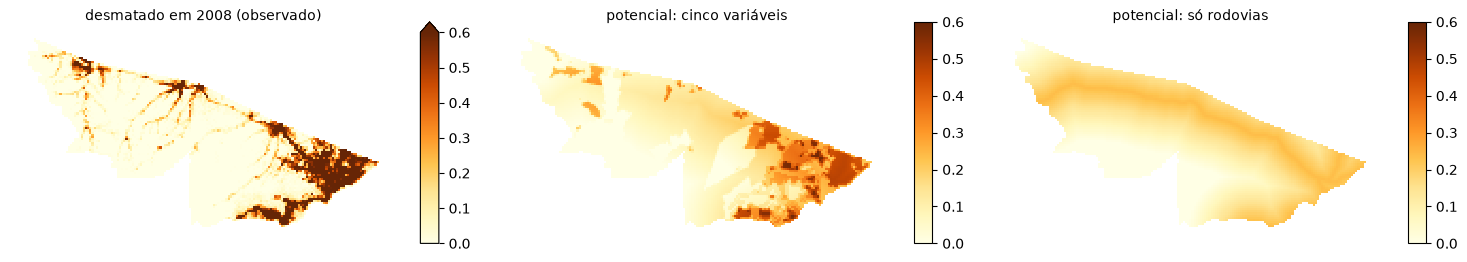

In [6]:
SO_RODOVIAS = ["rodovias"]    # 🔧 experimente ["assentamen"] ou ["rodovias", "assentamen"]

reduzido = sm.OLS(acre["d"].astype(float), sm.add_constant(acre[SO_RODOVIAS].astype(float))).fit()
pot_completo = ajuste.predict(X)
pot_reduzido = reduzido.predict(sm.add_constant(acre[SO_RODOVIAS].astype(float)))
print(f"R²: completo {ajuste.rsquared:.3f}, só {SO_RODOVIAS}: {reduzido.rsquared:.3f}")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, (valores, titulo) in zip(eixos, [(acre["d"], "desmatado em 2008 (observado)"),
                                        (pot_completo, "potencial: cinco variáveis"),
                                        (pot_reduzido, f"potencial: só {', '.join(SO_RODOVIAS)}")]):
    acre.assign(v=np.clip(valores, 0, 1)).plot(column="v", cmap="YlOrBr", vmin=0, vmax=0.6, ax=ax, legend=True)
    ax.set_title(titulo, fontsize=10); ax.set_axis_off()
plt.tight_layout()

✏️ **Pergunta 2.** O que o potencial de uma variável só não consegue representar? Onde ele erra mais?

## 2. Alocação discreta: uma classe por célula

No lab01 cada célula tem frações de floresta, desmatado e outros, e a alocação **contínua** muda essas frações aos poucos. Em muitos estudos o dado é um mapa de classes (como o MapBiomas ou o PRODES): cada célula é floresta **ou** desmatada. A alocação **discreta** troca a classe da célula inteira. É o CLUE-S (Verburg et al., 2002), que o LuccME chama de `DClueSLike`.

O lab15 do LuccME usa células de cerca de 500 m em Mojuí dos Campos, junto à BR-163, no Pará, de 1999 a 2004. A demanda é em número de células; o potencial é uma **regressão logística**, que dá a probabilidade de cada célula ser desmatada:

$$P(d) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots)}}$$

In [7]:
USOS_M = ["f", "d", "o"]
VARIAVEIS_M = ["media_decl", "dist_area_", "dist_br", "dist_curua", "dist_rios_", "dist_estra"]
DEMANDA_M = pd.DataFrame([[5706, 205, 3], [5658, 253, 3], [5611, 300, 3], [5563, 348, 3], [5516, 395, 3], [5468, 443, 3]],
                         index=range(1999, 2005), columns=USOS_M)
LOGISTICA = [   # coeficientes do script do lab15: floresta, desmatado, outros
    LogisticRegressionSpec(const=-2.34187976925989, elasticity=0.0, betas={
        "media_decl": -0.0272710076327129, "dist_area_": 4.30977432375496, "dist_br": 3.10319957497883,
        "dist_curua": 0.445414024051873, "dist_rios_": 47.3556329553235, "dist_estra": 38.4966894254506}),
    LogisticRegressionSpec(const=-0.100351497277102, elasticity=0.6, betas={
        "media_decl": 0.0581358851690861, "dist_area_": -0.974998890251365, "dist_br": -2.51650696123426,
        "dist_curua": -1.26742746441679, "dist_rios_": -40.3646901047482, "dist_estra": -23.0841140199094}),
    LogisticRegressionSpec(const=0.01, elasticity=0.5, betas={}),
]
DEMANDA_M

,f,d,o
1999,5706,205,3
2000,5658,253,3
2001,5611,300,3
2002,5563,348,3
2003,5516,395,3
2004,5468,443,3


Dois elementos novos na alocação discreta:

- a **matriz de transição** diz quais mudanças são permitidas. Aqui, floresta pode virar desmatado, mas desmatado não volta a ser floresta;
- a **elasticidade** de cada classe (0,6 para o desmatado) é a resistência a mudar: quanto maior, mais a célula tende a ficar como está.

A função `simular_discreto` monta o lab15. O parâmetro `protegida` será usado na Parte 4.

In [8]:
lin_m = moju["row"].astype(int).values - moju["row"].astype(int).min()
col_m = moju["col"].astype(int).values - moju["col"].astype(int).min()
FORMA_M = (lin_m.max() + 1, col_m.max() + 1)
ANOS_M = list(DEMANDA_M.index)


def grade_moju():
    grade = RasterBackend(shape=FORMA_M)
    mascara = np.zeros(FORMA_M, dtype=np.float32); mascara[lin_m, col_m] = 1
    grade.set("mask", mascara)
    for c in USOS_M + VARIAVEIS_M:
        a = np.zeros(FORMA_M, dtype=np.float32); a[lin_m, col_m] = moju[c].astype(float).values
        grade.set(c, a)
    return grade


def guardar(grade, mapas):
    class Fotografo(Model):
        def execute(self):
            mapas.append({c: np.asarray(grade.get(c), dtype=np.float64)[lin_m, col_m].copy() for c in ["f", "d"]})
    Fotografo()


def simular_discreto(max_difference=10, protegida=None):
    """lab15: potencial logístico + CLUE-S. `protegida`: células onde nada pode mudar (região 2)."""
    grade = grade_moju()
    transicoes = [[[1, 1, 0], [0, 1, 0], [0, 0, 1]]]          # região 1: f → d permitido
    potencial = [copy.deepcopy(LOGISTICA)]
    if protegida is not None:
        regiao = np.ones(FORMA_M, dtype=np.int32); regiao[lin_m[protegida], col_m[protegida]] = 2
        grade.set("region", regiao)
        transicoes.append([[1, 0, 0], [0, 1, 0], [0, 0, 1]])   # região 2: nenhuma mudança
        potencial.append(copy.deepcopy(LOGISTICA))
    env = Environment(end_time=len(ANOS_M) - 1)
    dem = DemandPreComputedValues(annual_demand=DEMANDA_M.values.tolist(), land_use_types=USOS_M)
    PotentialDLogisticRegression(backend=grade, potential_data=potencial, land_use_types=USOS_M)
    alo = AllocationDClueSLike(backend=grade, demand=dem, land_use_types=USOS_M, transition_matrix=transicoes,
                               cell_area=1.0, max_difference=max_difference, max_iteration=1000, factor_iteration=0.0001)
    mapas = []
    guardar(grade, mapas)
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return dict(zip(ANOS_M, mapas)), list(alo.iterations_per_step)

O script do lab15 usa tolerância de 300 células. Veja o que acontece:

In [9]:
original, iteracoes = simular_discreto(max_difference=300)
print("iterações:", iteracoes)
print("células desmatadas por ano:", [int(m["d"].sum()) for m in original.values()])
print("demanda:                   ", DEMANDA_M["d"].tolist())

iterações: [0, 0, 0, 0, 0, 0]
células desmatadas por ano: [205, 205, 205, 205, 205, 205]
demanda:                    [205, 253, 300, 348, 395, 443]


O mesmo problema do lab01 no encontro 9, só que pior: a demanda cresce 238 células no período, menos que a tolerância de 300, e a alocação aceita "não mudar nada" em todos os anos. O `luccme-goldens` tem uma variante com tolerância de 10 células, que usamos daqui em diante. Antes, a verificação contra o LuccME:

In [10]:
discreto, iter_d = simular_discreto(max_difference=10)
golden = pd.read_csv(locais["lab15_md10.csv.gz"]).set_index(["year", "row", "col"])
indice = pd.MultiIndex.from_arrays([moju["row"].astype(int).values, moju["col"].astype(int).values])
diferenca = max(np.abs(discreto[a]["d"] - golden.loc[a].reindex(indice)["d_out"].values).max() for a in ANOS_M)
print("iterações no DisSLUCC:", iter_d)
print("iterações no TerraME:  [0, 67, 56, 56, 61, 61]")
print("células diferentes do LuccME, em qualquer ano:", int(diferenca))
print("células desmatadas por ano:", [int(m["d"].sum()) for m in discreto.values()])

iterações no DisSLUCC: [0, 67, 56, 56, 61, 61]
iterações no TerraME:  [0, 67, 56, 56, 61, 61]
células diferentes do LuccME, em qualquer ano: 0
células desmatadas por ano: [205, 244, 291, 341, 388, 442]


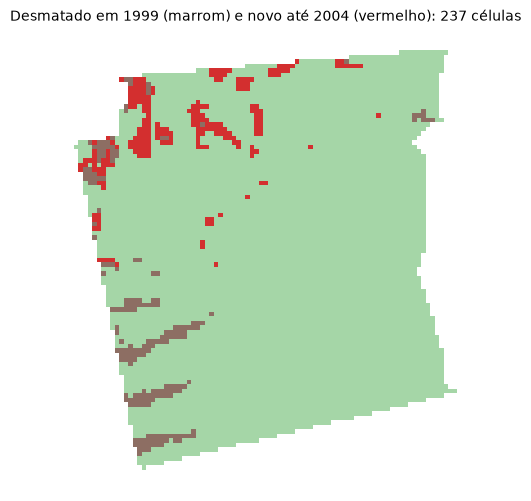

In [11]:
novas = (discreto[2004]["d"] == 1) & (moju["d"].values == 0)
estado = np.where(moju["d"].values == 1, 1, np.where(novas, 2, 0))
fig, ax = plt.subplots(figsize=(6, 6))
moju.assign(e=estado).plot(column="e", categorical=True, ax=ax,
                           cmap=plt.matplotlib.colors.ListedColormap(["#a5d6a7", "#8d6e63", "#d32f2f"]))
ax.set_title(f"Desmatado em 1999 (marrom) e novo até 2004 (vermelho): {novas.sum()} células", fontsize=10)
ax.set_axis_off()

## 3. Contínua × discreta no mesmo lugar

Para comparar as duas alocações na mesma área, ajustamos uma regressão **linear** aos dados de Mojuí dos Campos (como na Parte 1) e rodamos a alocação contínua, com a mesma demanda.

In [12]:
Xm = sm.add_constant(moju[VARIAVEIS_M].astype(float))
linear = {u: sm.OLS(moju[u].astype(float), Xm).fit() for u in ["f", "d"]}
print(f"R² da regressão linear: floresta {linear['f'].rsquared:.2f}, desmatado {linear['d'].rsquared:.2f}")


def spec(r):
    return RegressionSpec(const=float(r.params["const"]), betas={k: float(v) for k, v in r.params.items() if k != "const"})


def simular_continuo(max_difference=10):
    grade = grade_moju()
    env = Environment(end_time=len(ANOS_M) - 1)
    dem = DemandPreComputedValues(annual_demand=DEMANDA_M.values.tolist(), land_use_types=USOS_M)
    pot = PotentialLinearRegression(backend=grade, demand=dem, land_use_types=USOS_M, land_use_no_data="o",
                                    potential_data=[[spec(linear["f"]), spec(linear["d"]), RegressionSpec(const=0.0)]])
    AllocationClueLike(backend=grade, demand=dem, potential=pot, land_use_types=USOS_M,
                       static={"f": -1, "d": -1, "o": 1}, complementar_lu="f", cell_area=1.0,
                       allocation_data=[AllocationSpec(static=s, min_value=0, max_value=1, min_change=0, max_change=1)
                                        for s in (-1, -1, 1)],
                       max_difference=max_difference, cell_correction=False)
    mapas = []
    guardar(grade, mapas)
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return dict(zip(ANOS_M, mapas))

continuo = simular_continuo()
ganho = continuo[2004]["d"] - continuo[1999]["d"]
print(f"desmatado em 2004: contínuo {continuo[2004]['d'].sum():.0f} células, discreto {discreto[2004]['d'].sum():.0f}")
print(f"contínuo: {(ganho > 0.001).sum()} células ganham alguma fração (no máximo {ganho.max():.2f})")
print(f"discreto: {novas.sum()} células mudam por inteiro")

R² da regressão linear: floresta 0.11, desmatado 0.11


desmatado em 2004: contínuo 443 células, discreto 442
contínuo: 3948 células ganham alguma fração (no máximo 0.20)
discreto: 237 células mudam por inteiro


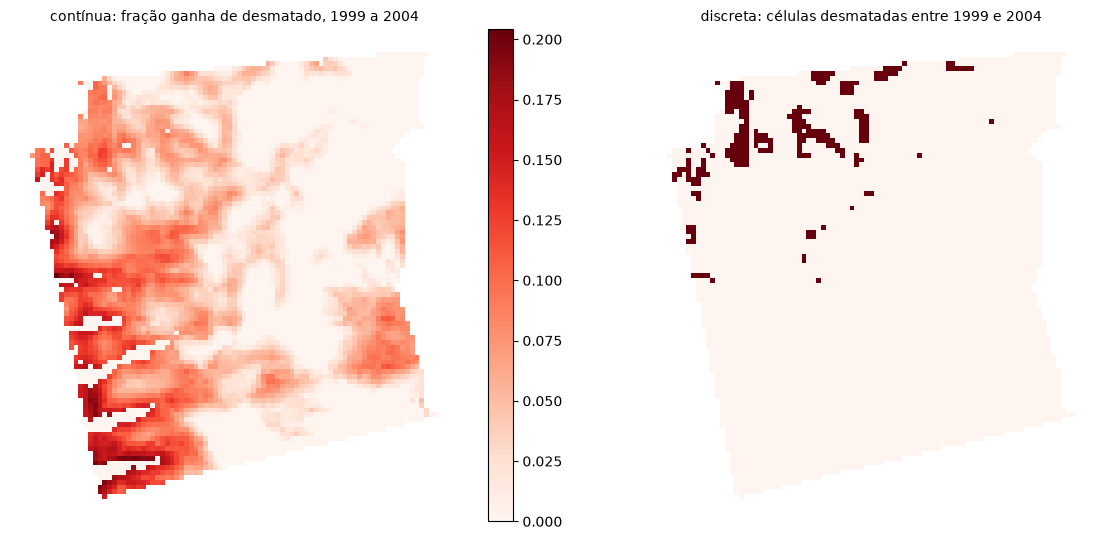

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.5))
moju.assign(v=ganho).plot(column="v", cmap="Reds", vmin=0, ax=eixos[0], legend=True)
eixos[0].set_title("contínua: fração ganha de desmatado, 1999 a 2004", fontsize=10)
moju.assign(v=novas.astype(int)).plot(column="v", cmap="Reds", vmin=0, vmax=1, ax=eixos[1])
eixos[1].set_title("discreta: células desmatadas entre 1999 e 2004", fontsize=10)
for ax in eixos: ax.set_axis_off()
plt.tight_layout()

As duas atendem a mesma demanda, mas o resultado tem outra **natureza**: a contínua espalha o desmatamento em pequenas frações por milhares de células; a discreta converte poucas células inteiras.

O **lugar** também mudou, e isso não vem da alocação: vem do potencial. A contínua usa a regressão linear que acabamos de ajustar; a discreta usa a logística do lab15, que concentra a mudança no norte. A regressão linear é dominada por `dist_area_` e `dist_curua`, com coeficientes enormes e de sinais opostos: as duas distâncias são quase a mesma variável (correlação de 0,96), e a regressão "divide" o efeito entre elas de forma instável. Antes de ajustar, vale olhar a correlação entre os drivers e deixar só um de cada par muito parecido. Além disso, uma reta se ajusta mal a um dado que só vale 0 ou 1 (R² de 0,11): é por isso que, com mapas de classes, o potencial costuma ser logístico. Para comparar só as alocações seria preciso o mesmo potencial nas duas, o que o DisSLUCC ainda não permite (cada alocação tem o seu tipo de potencial).

✏️ **Pergunta 3.** O seu projeto tem dados em frações (cobertura por célula) ou em classes (um mapa de uso)? Qual alocação combina com ele, e qual o tamanho de célula?

Existe uma terceira alocação no DisSLUCC, a **contínua com saturação** (`AllocationClueLikeSaturation`, lab03 do LuccME): quando uma célula se aproxima do limite de uma classe, a mudança passa para as vizinhas. Não a usamos hoje.

## 4. Restrições: proteger uma faixa ao longo dos rios

Uma restrição proíbe a mudança numa parte da área: uma unidade de conservação, uma terra indígena, uma faixa de preservação. No CLUE-S ela entra como uma **região** com outra matriz de transição, em que nada pode mudar.

Protegemos as células de floresta a menos de 0,0045° (cerca de 500 m, uma célula) do rio mais próximo, segundo a variável `dist_rios_`, que está em graus como as demais distâncias deste espaço celular. É um exercício, não a regra das Áreas de Preservação Permanente, cuja largura depende do rio.

In [14]:
FAIXA = 0.0045    # graus (≈ 500 m); 🔧 experimente 0.009

protegida = (moju["dist_rios_"].values < FAIXA) & (moju["f"].values == 1)
com_restricao, iter_r = simular_discreto(max_difference=10, protegida=protegida)
novas_r = (com_restricao[2004]["d"] == 1) & (moju["d"].values == 0)

print(f"células protegidas: {protegida.sum()}")
print(f"desmatado em 2004: sem restrição {discreto[2004]['d'].sum():.0f}, com restrição {com_restricao[2004]['d'].sum():.0f}")
print(f"novas dentro da faixa: sem restrição {(novas & protegida).sum()}, com restrição {(novas_r & protegida).sum()}")
print(f"células desmatadas só no cenário com restrição: {(novas_r & ~novas).sum()}")

células protegidas: 1367
desmatado em 2004: sem restrição 442, com restrição 444
novas dentro da faixa: sem restrição 174, com restrição 0
células desmatadas só no cenário com restrição: 176


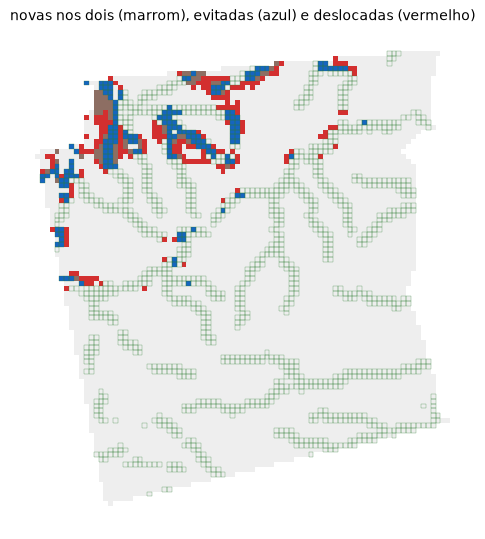

In [15]:
tipo = np.select([novas & novas_r, novas & ~novas_r, ~novas & novas_r], [1, 2, 3], 0)
cores = plt.matplotlib.colors.ListedColormap(["#eeeeee", "#8d6e63", "#1565c0", "#d32f2f"])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
moju.assign(t=tipo).plot(column="t", cmap=cores, vmin=0, vmax=3, ax=ax)
moju[protegida].boundary.plot(ax=ax, color="#2e7d32", linewidth=0.2)
ax.set_title("novas nos dois (marrom), evitadas (azul) e deslocadas (vermelho)", fontsize=10)
ax.set_axis_off()

A restrição não reduziu o desmatamento: a demanda é a mesma, e a alocação desmatou fora da faixa o que não pôde desmatar dentro dela. Esse deslocamento é o **vazamento**, um dos efeitos mais discutidos na avaliação de áreas protegidas.

✏️ **Pergunta 4.** Que cenário você precisaria montar para que a proteção da faixa reduzisse de fato o desmatamento? Lembre do encontro 9: o que decide quanto, e o que decide onde?

## Para casa: o potencial do seu projeto

Com a grade montada no encontro 10, ajuste uma regressão para a classe que muda no seu projeto. O esqueleto, para um cubo com `floresta` e `pastagem` em dois anos e uma distância `dist_estradas`:

```python
from disscube.client import CubeClient
import statsmodels.api as sm

cubo = CubeClient("cubo_projeto/catalog.db", "cubo_projeto/store")
ds = cubo.to_dataset(["pastagem", "dist_estradas"], grid_id="projeto_500m")
tabela = (ds.isel(time=0) if "time" in ds.dims else ds).to_dataframe().dropna()   # o primeiro ano
X = sm.add_constant(tabela[["dist_estradas"]])
print(sm.OLS(tabela["pastagem"], X).fit().summary())
```

Quem não montou a grade própria pode usar o cubo do encontro 10: `CubeClient("cubo/catalog.db", "cubo/store")`, variáveis `prodes_10` e `distroads`, grade `amazonia_50km` (R² de 0,16 com a distância às rodovias).

1. Ajuste com duas ou três variáveis. Os sinais fazem sentido? Qual o R²?
2. Calcule o efeito de um desvio padrão de cada variável (Parte 1).
3. Traga a tabela para o encontro 12, onde vamos variar os coeficientes e ver o que muda no mapa.